# Where may I fly, advanced: zone geometry, a map of allowed height, flight levels and the AIRAC cycle

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/eu_rules_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Where and how may I fly](https://openskylab.space/edu_viz_eu_rules.html) · [česká verze](eu_rules_pro_cs.ipynb)

The advanced version of the notebook on UAS geographical zones. On current ŘLP data you check whether the geometry of zones matches their description, build a map of allowed flight height around Brno from the grids, compute from METAR reports how high flight levels really are, check the effective dates of zones against the AIRAC cycle and draw a vertical cross-section of the zones from Bystrc to Tuřany airport over the real terrain. This is a teaching aid, not legal advice: before a flight always check the zones in the DroneMap app and the conditions in the CAA measures of general nature (OOP).

**Goal:** measure the radii of circular zones and compare them with the description, combine the GRID_CTR and GRID_ATZ grids into a map of allowed height, convert flight levels to true altitude from QNH and temperature, check effective dates against the AIRAC cycle and build a vertical cross-section of the zones over the DMR 5G terrain.

**Data:** UAS geographical zones as GeoJSON (reference boundaries) from the ŘLP page https://aim.rlp.cz/?lang=en&p=uas-gz, downloaded at run time, except layers larger than the chosen limit; METAR reports of Brno-Tuřany airport (LKTB) for the last 7 days from the Aviation Weather Center (NOAA); terrain elevation from the Digital terrain model of the Czech Republic, 5th generation (DMR 5G, ČÚZK). The conversion of a flight level to true altitude uses the ICAO standard atmosphere with the temperature adjusted to the airport; it is an approximation.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 60 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and zones

We load the list of current zones from the ŘLP page and download all layers up to the chosen size limit and both grids. Downloading takes about a minute.

In [1]:
%pip install -q shapely pyproj rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, html, time, datetime as dt, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point, LineString, box
import shapely
from pyproj import Transformer
import rasterio

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

In [3]:
AIM = "https://aim.rlp.cz"
def get(url, tries=4, **kw):
    for i in range(tries):
        try:
            r = requests.get(url, timeout=300, **kw); r.raise_for_status(); return r
        except requests.RequestException as e:
            print(url.split("/")[-1], type(e).__name__, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError(f"Could not download {url}")

page = get(f"{AIM}/?lang=en&p=uas-gz").content.decode("utf-8")
rows = []
for tr in re.findall(r"<tr.*?</tr>", page, re.S):
    href = re.search(r'href="(/data/uas/[^"]+\.json)"', tr)
    cols = [re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", c))).strip() for c in re.findall(r"<td[^>]*>(.*?)</td>", tr, re.S)]
    if href and len(cols) >= 4 and "/actual/" in href.group(1):
        mb = re.search(r"([\d.,]+)\s*(kB|MB)", cols[3])
        rows.append({"code": cols[2].replace(".json", ""), "desc": cols[1], "MB": float(mb.group(1).replace(",", ".")) * (1e-3 if mb.group(2) == "kB" else 1), "url": AIM + href.group(1)})
zones = pd.DataFrame(rows).set_index("code")
MAX_MB = 20                   # ◀ parameter: largest file to download (MB); both grids are always downloaded
T_UTM = Transformer.from_crs(4326, 32633, always_xy=True)
to_utm = lambda g: shapely.transform(g, lambda xy: np.column_stack(T_UTM.transform(xy[:, 0], xy[:, 1])))
layers = {}
for code, z in zones.iterrows():
    if z.MB <= MAX_MB or code in ("GRID_CTR", "GRID_ATZ"):
        feats = [f for f in get(z.url).json()["features"] if f.get("geometry")]
        layers[code] = pd.DataFrame({"geom": [shape(f["geometry"]) for f in feats], **{k: [f["properties"].get(k) for f in feats] for k in ("ident", "vertical_limit", "effective_date")}})
print(f"downloaded {len(layers)} layers, {sum(len(v) for v in layers.values())} features; large layers left out:", ", ".join(c for c in zones.index if c not in layers))

downloaded 24 layers, 76189 features; large layers left out: LKR311A, LKR311B, LKR316, LKR317C, LKR317D, LKR318C, ed_318_a1_a2_all


## 2. Does the geometry of zones match the description?

For zones that the description defines by a distance from a point (aerodrome reference point ARP, heliport HRP), we measure the radius in the data: the radius of a circle with the same area as the outer boundary of the feature. The computation runs in metres in UTM 33N coordinates.

radius r_eq in the data (m):
                                                     description features by description (m)  min 25 % median 75 %  max
LKR315A  Area around Uncontrolled Aerodromes up to 5500 m from A       82               5500 1259 5498   5498 5499 9465
LKR315B  Area around Sport Flying Facilities up to 1500 m from A       75               1550  947  956    965  977  989
LKR314D                       Circle with Radius 5.5 km from ARP        1               5500 5498 5498   5498 5498 5498
LKR315C  Area around Heliports within 3000–1000 m, 1000–200 m, a      222      3000/1000/200  126  130    646 1921 1978
LKR315D  Area around Public Interest Sites (Backup Heliports) wi      195      3000/1000/200  126  130    645 1918 1976


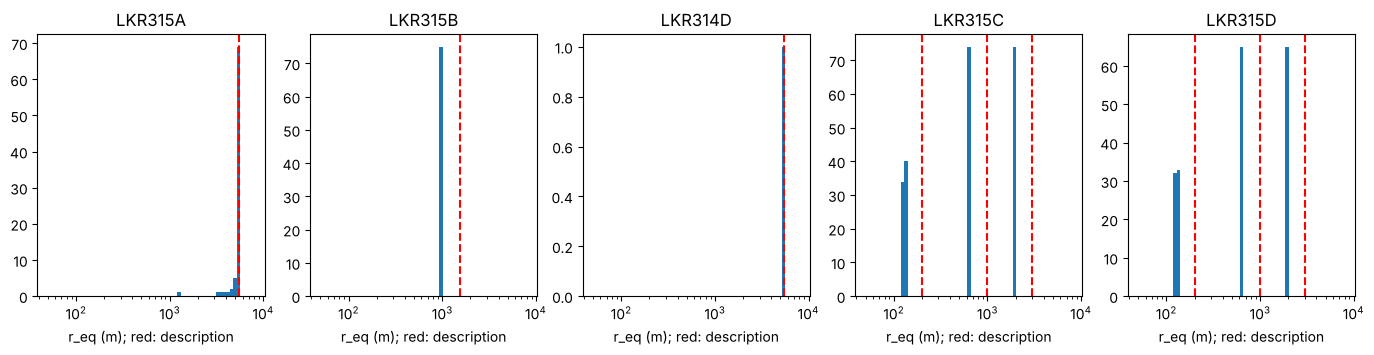

In [4]:
CHECK = {"LKR315A": [5500], "LKR315B": [1550], "LKR314D": [5500], "LKR315C": [3000, 1000, 200], "LKR315D": [3000, 1000, 200]}   # ◀ parameter: layer → radii according to the description on the ŘLP page (m)
rows, R = {}, {}
for code, r_desc in CHECK.items():
    g = layers[code].geom.map(lambda x: to_utm(shapely.make_valid(x)))
    ext = g.map(lambda x: shapely.Polygon(max(x.geoms, key=lambda q: q.area).exterior) if x.geom_type == "MultiPolygon" else shapely.Polygon(x.exterior))
    R[code] = np.sqrt(ext.map(lambda x: x.area).to_numpy() / np.pi)                 # radius of a circle with the same area as the outer boundary of the feature
    q = np.percentile(R[code], [0, 25, 50, 75, 100])
    rows[code] = {"description": zones.loc[code, "desc"][:55], "features": len(g), "by description (m)": "/".join(map(str, r_desc)),
                  "min": q[0], "25 %": q[1], "median": q[2], "75 %": q[3], "max": q[4]}
print("radius r_eq in the data (m):"); print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.0f}"))
fig, ax = plt.subplots(1, len(CHECK), figsize=(17, 3.4))
for a, (code, r_desc) in zip(ax, CHECK.items()):
    a.hist(R[code], bins=np.geomspace(50, 8000, 60), color="C0"); a.set_xscale("log")
    for r in r_desc: a.axvline(r, color="r", ls="--")
    a.set_title(code); a.set_xlabel("r_eq (m); red: description")
plt.show()

> **✏️ Task 1.** Which layers match the description and which do not? For LKR315A find features clearly smaller and larger than 5500 m and explain what may cause it (look at where they lie). For LKR315B, LKR315C and LKR315D compute by what percentage the radius in the data differs from the description on the ŘLP page. Find in the CAA measure of general nature for the LKR315 zones which distances apply, and decide what a pilot should follow: the description, or the zone boundary in DroneMap.

*Your answer:* 

## 3. A map of allowed height around Brno

The GRID_CTR grid (around controlled airports, 30″ cells) and the GRID_ATZ grid (areas of uncontrolled air traffic, 15″ cells) state in every cell up to what height above ground flight is allowed without further approval. We sample the area every 7.5″, so each point lies inside one cell. Besides that we count how many zones from the ground (GND) overlap at a point.

share of the area by allowed height from GRID_CTR and GRID_ATZ (%):
0 m                 14.5
1–30 m              12.4
31–60 m             12.8
61–90 m             10.3
91–119 m             3.6
120 m               29.6
outside the grid    16.8
share of the area in at least one zone from the ground (layers LKR312A, LKR312B, LKR313, LKR314A, LKR314B, LKR314C, LKR314D, LKR314E, LKR314F, LKR315A, LKR315B, LKR315C, LKR315D, LKR318A, LKR318B, LKR319): 80 %


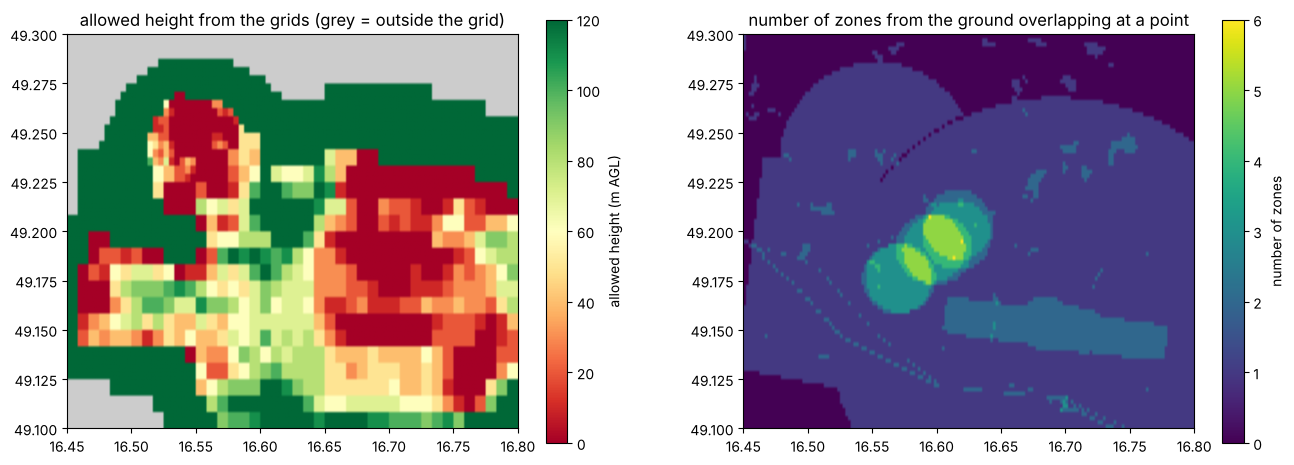

In [5]:
BBOX = (16.45, 49.10, 16.80, 49.30)   # ◀ parameter: area (longitude and latitude: west, south, east, north)
STEP = 1 / 480                        # 7.5″ step: half a GRID_ATZ cell, a quarter of a GRID_CTR cell
lon = np.arange(BBOX[0] + STEP / 2, BBOX[2], STEP); lat = np.arange(BBOX[1] + STEP / 2, BBOX[3], STEP)
LON, LAT = np.meshgrid(lon, lat)
hmax = lambda txt: float(re.search(r"-\s*([\d.]+)\s*m\s*AGL", txt).group(1))
allowed = np.full(LON.shape, np.nan)
for code in ("GRID_CTR", "GRID_ATZ"):
    for g, v in zip(layers[code].geom, layers[code].vertical_limit):
        if g.intersects(box(*BBOX)):
            inside = shapely.contains_xy(g, LON, LAT)
            allowed[inside] = np.fmin(allowed[inside], hmax(v))
restr = [c for c in layers if c.startswith(("LKR312", "LKR313", "LKR314", "LKR315", "LKR318", "LKR319"))]   # zones from the ground (GND)
nzones = np.zeros(LON.shape, int)
for code in restr:
    for g in layers[code].geom:
        if g.intersects(box(*BBOX)):
            nzones += shapely.contains_xy(g, LON, LAT)
classes = pd.cut(pd.Series(allowed.ravel()), [-1, 0, 30, 60, 90, 119, 120], labels=["0 m", "1–30 m", "31–60 m", "61–90 m", "91–119 m", "120 m"])
share = (100 * classes.value_counts(normalize=False) / allowed.size).reindex(classes.cat.categories)
share["outside the grid"] = 100 * np.isnan(allowed).mean()
print("share of the area by allowed height from GRID_CTR and GRID_ATZ (%):"); print(share.round(1).to_string())
print(f"share of the area in at least one zone from the ground (layers {', '.join(restr)}): {100 * (nzones > 0).mean():.0f} %")
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ext = (BBOX[0], BBOX[2], BBOX[1], BBOX[3]); asp = 1 / np.cos(np.radians(LAT.mean()))
im = ax[0].imshow(allowed, origin="lower", extent=ext, cmap="RdYlGn", vmin=0, vmax=120, aspect=asp); plt.colorbar(im, ax=ax[0], label="allowed height (m AGL)")
ax[0].set_title("allowed height from the grids (grey = outside the grid)"); ax[0].set_facecolor("0.8")
im = ax[1].imshow(nzones, origin="lower", extent=ext, cmap="viridis", aspect=asp); plt.colorbar(im, ax=ax[1], label="number of zones")
ax[1].set_title("number of zones from the ground overlapping at a point")
plt.show()

> **✏️ Task 2.** What share of the area may you fly over at 120 m according to the grids, what share only up to 30 m, and where may you not fly at all? Where is the allowed height 0 m, and why there (compare with the position of Tuřany airport, Medlánky airfield and the heliports in the right map)? Does the grey area outside the grid mean you may fly there without restrictions? Remember the large layers we did not download.

*Your answer:* 

## 4. How high is a flight level?

A flight level FL is a pressure altitude in hundreds of feet at the standard pressure of 1013.25 hPa. The true altitude of the level depends on the pressure at the ground (QNH) and on the air temperature: in warm air it lies higher, in cold air lower. We take QNH and temperature from METAR reports for the last 7 days and compute the true altitude of the levels that are the lower limit of LKR320A areas.

LKTB: 336 METAR reports, QNH 1006–1029 hPa, temperature -1–13 °C, airport 233 m a.s.l.
      FL × 100 ft (m)  min (m a.s.l.)  max (m a.s.l.)  range (m)
FL65             1981            1888            2095        207
FL95             2896            2772            3005        232


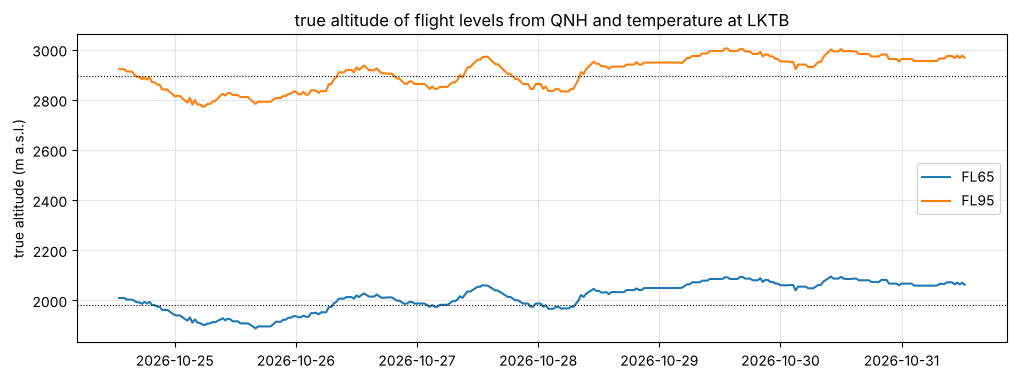

In [6]:
STATION = "LKTB"              # ◀ parameter: the airport whose QNH and temperature we use (METAR reports)
FLS = [65, 95]                # ◀ parameter: flight levels (e.g. lower limits of LKR320A areas)
met = pd.DataFrame(get("https://aviationweather.gov/api/data/metar", params={"ids": STATION, "format": "json", "hours": 168}).json())
met["time"] = pd.to_datetime(met.reportTime); met = met.dropna(subset=["altim", "temp"]).sort_values("time").set_index("time")
h_s = float(met.elev.iloc[0])
pa = lambda p: 44330.77 * (1 - (p / 1013.25) ** 0.190263)                 # pressure altitude (m) in ISA
def true_alt(fl, qnh, t_s):
    """True altitude of a flight level: first the altitude on QNH, then a correction for the temperature of the layer between the airport and the level."""
    z_q = fl * 100 * 0.3048 - pa(qnh)                                       # altitude on an altimeter set to QNH
    t_isa = 288.15 - 0.0065 * (h_s + z_q) / 2                               # mean temperature of the layer in ISA
    t_act = t_s + 273.15 - 0.0065 * (z_q - h_s) / 2                         # mean actual temperature of the layer (lapse 6.5 K/km)
    return h_s + (z_q - h_s) * t_act / t_isa
fig, ax = plt.subplots(figsize=(12, 4))
rows = {}
for fl in FLS:
    z = true_alt(fl, met.altim, met.temp)
    ax.plot(z.index, z, label=f"FL{fl}"); ax.axhline(fl * 100 * 0.3048, color="k", lw=0.8, ls=":")
    rows[f"FL{fl}"] = {"FL × 100 ft (m)": fl * 100 * 0.3048, "min (m a.s.l.)": z.min(), "max (m a.s.l.)": z.max(), "range (m)": z.max() - z.min()}
print(f"{STATION}: {len(met)} METAR reports, QNH {met.altim.min():.0f}–{met.altim.max():.0f} hPa, temperature {met.temp.min():.0f}–{met.temp.max():.0f} °C, airport {h_s:.0f} m a.s.l.")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.0f}"))
ax.set_ylabel("true altitude (m a.s.l.)"); ax.legend(); ax.grid(alpha=0.3); ax.set_title(f"true altitude of flight levels from QNH and temperature at {STATION}")
plt.show()

> **✏️ Task 3.** By how many metres did the true altitude of FL65 and FL95 change during the week? What affects it more, QNH or temperature? Compute how many metres of height correspond to a change of QNH by 1 hPa. How high above Děvín (about 550 m a.s.l.) does the LKTB4 area (FL65) start in the lowest and the highest case? Why are higher limits in aviation given as flight levels, although their true altitude varies?

*Your answer:* 

## 5. When zones apply: the AIRAC cycle

Changes to aeronautical information are published for the fixed dates of the AIRAC cycle, which follow every 28 days, and ŘLP updates the zone data in line with this cycle. Every zone feature has an effective date (effective_date). We find out which effective dates are AIRAC dates.

In [7]:
AIRAC_REF = pd.Timestamp("2024-01-25", tz="UTC")     # a known AIRAC date (cycle 2401), cycles follow every 28 days
eff = pd.concat([pd.DataFrame({"layer": c, "effective": pd.to_datetime(d.effective_date)}) for c, d in layers.items()])
tab = eff.groupby("effective")["layer"].agg(["count", lambda s: ", ".join(sorted(set(s)))])
tab.columns = ["features", "layers"]
days = (tab.index - AIRAC_REF).days
tab["AIRAC date"] = days % 28 == 0
tab["cycle"] = [f"{(AIRAC_REF + pd.Timedelta(days=28 * (d // 28))).year % 100:02d}{1 + ((AIRAC_REF + pd.Timedelta(days=28 * (d // 28))) - pd.Timestamp(f'{(AIRAC_REF + pd.Timedelta(days=28 * (d // 28))).year}-01-01', tz='UTC')).days // 28:02d}" if d % 28 == 0 else "" for d in days]
pd.set_option("display.max_colwidth", 80)
print(tab.to_string())
today = pd.Timestamp.now(tz="UTC").normalize()
nxt = AIRAC_REF + pd.Timedelta(days=28 * ((today - AIRAC_REF).days // 28 + 1))
print(f"today {today:%Y-%m-%d}, next AIRAC date {nxt:%Y-%m-%d}")

                           features                                                                                                                                                                                                         layers  AIRAC date cycle
effective                                                                                                                                                                                                                                                           
2025-09-01 00:00:00+00:00     76046  GRID_ATZ, GRID_CTR, LKR311C, LKR311D, LKR312A, LKR312B, LKR313, LKR314A, LKR314B, LKR314C, LKR314D, LKR314E, LKR314F, LKR315A, LKR315B, LKR315C, LKR315D, LKR317A, LKR317B, LKR318A, LKR318B, LKR319, LKR320A       False      
2025-10-21 00:00:00+00:00         2                                                                                                                                                                                      

> **✏️ Task 4.** Which effective dates match the AIRAC cycle and which do not? Which layers changed most often, and why those? The OOPUAS-0055 zone has a date outside the cycle: find on the ŘLP page or in DroneMap what zone it is, and explain why it can be created outside the cycle. When is the next AIRAC date, and what do you do before a flight after that date?

*Your answer:* 

## 6. A vertical cross-section of the zones

Along the line from Bystrc to Brno-Tuřany airport we sample the terrain from DMR 5G every 25 m, and for every zone the line crosses we convert the lower and upper limit to altitude (AGL above the terrain, FL as in the standard atmosphere). The black line is the terrain plus the allowed height from the grids.

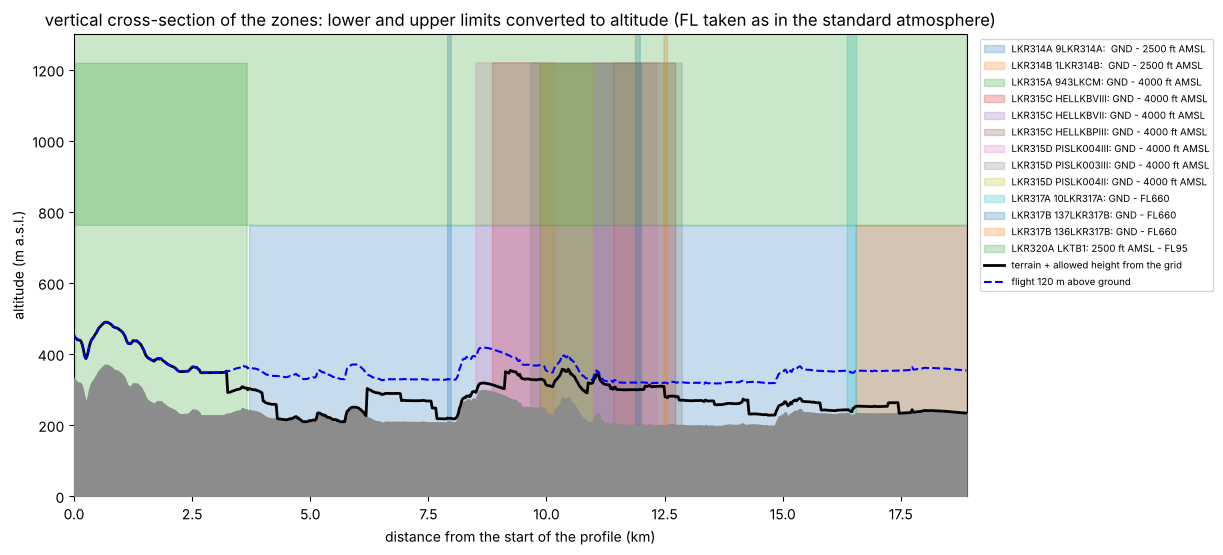

a flight at 120 m above ground is possible according to the grids along 17 % of the profile; terrain 196–369 m a.s.l.


In [8]:
A = (49.2467, 16.4798)        # ◀ parameter: start of the profile (Bystrc, Kozí horka)
B = (49.1510, 16.6940)        # ◀ parameter: end of the profile (Brno-Tuřany airport)
FLIGHT_AGL = 120              # ◀ parameter: planned flight height above ground (m)
T_JTSK = Transformer.from_crs(4326, 5514, always_xy=True)
(xa, xb), (ya, yb) = T_JTSK.transform([A[1], B[1]], [A[0], B[0]])
dem, tr = cuzk_raster("dmr5g", min(xa, xb) - 100, min(ya, yb) - 100, max(xa, xb) + 100, max(ya, yb) + 100, res=10.0)
n = int(np.hypot(xb - xa, yb - ya) // 25) + 1
d = np.linspace(0, np.hypot(xb - xa, yb - ya), n); xs = xa + (xb - xa) * d / d[-1]; ys = ya + (yb - ya) * d / d[-1]
col, row = ~tr * (xs, ys)
terr = dem[np.clip(row.astype(int), 0, dem.shape[0] - 1), np.clip(col.astype(int), 0, dem.shape[1] - 1)]
plon = np.linspace(A[1], B[1], n); plat = np.linspace(A[0], B[0], n)       # over 15 km a linear interpolation in geographic coordinates is enough
def amsl(txt, ground):
    s = txt.strip().upper().replace(" ", "")
    if s in ("GND", "SFC"): return ground
    if s.startswith("FL"): return np.full_like(ground, float(s[2:]) * 100 * 0.3048)
    m = re.match(r"([\d.]+)(FT|M)(AGL|AMSL|MSL)", s)
    v = float(m.group(1)) * (0.3048 if m.group(2) == "FT" else 1)
    return ground + v if m.group(3) == "AGL" else np.full_like(ground, v)
line = LineString(zip(plon, plat))
fig, ax = plt.subplots(figsize=(15, 6))
ax.fill_between(d / 1000, 0, terr, color="0.55", zorder=3)
k = 0
for code, df in layers.items():
    if code.startswith("GRID"): continue
    for g, ident, vl in zip(df.geom, df.ident, df.vertical_limit):
        if not g.intersects(line): continue
        inside = shapely.contains_xy(g, plon, plat)
        lo, hi = vl.split("-", 1)
        ax.fill_between(d / 1000, amsl(lo, terr), amsl(hi, terr), where=inside, alpha=0.25, color=f"C{k % 10}", label=f"{code} {ident}: {vl}"); k += 1
grid_h = np.full(n, np.nan)
for code in ("GRID_CTR", "GRID_ATZ"):
    for g, v in zip(layers[code].geom, layers[code].vertical_limit):
        if g.intersects(line):
            inside = shapely.contains_xy(g, plon, plat); grid_h[inside] = np.fmin(grid_h[inside], hmax(v))
ax.plot(d / 1000, terr + grid_h, "k", lw=2, zorder=4, label="terrain + allowed height from the grid")
ax.plot(d / 1000, terr + FLIGHT_AGL, "b--", zorder=4, label=f"flight {FLIGHT_AGL} m above ground")
ax.set_ylim(0, 1300); ax.set_xlim(0, d[-1] / 1000)
ax.set_xlabel("distance from the start of the profile (km)"); ax.set_ylabel("altitude (m a.s.l.)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); fig.subplots_adjust(right=0.72); ax.set_title("vertical cross-section of the zones: lower and upper limits converted to altitude (FL taken as in the standard atmosphere)")
plt.show()
ok = np.nan_to_num(grid_h, nan=120) >= FLIGHT_AGL
print(f"a flight at {FLIGHT_AGL} m above ground is possible according to the grids along {100 * ok.mean():.0f} % of the profile; terrain {terr.min():.0f}–{terr.max():.0f} m a.s.l.")

> **✏️ Task 5.** Along what percentage of the profile may you fly at 120 m above ground according to the grids, and where does the allowed height drop to zero? Which zones does the profile cross from the ground and which start high above the drone? Set FLIGHT_AGL to 50 m: how does the result change? Why is it not enough for a drone flight to know only the zones the take-off site falls into?

*Your answer:* 

> **✏️ Extension (optional).** Set BBOX, A, B and STATION to the area around Václav Havel Airport (STATION = "LKPR", end of the profile 50.10° N, 14.26° E) and compare the map of allowed height and the cross-section with Brno.

*Your answer:* 

---
### Data sources and references

- UAS geographical zones: Air Navigation Services of the Czech Republic (ŘLP ČR), AIM, https://aim.rlp.cz/?lang=en&p=uas-gz; zone map: https://dronemap.gov.cz
- Commission Implementing Regulation (EU) 2019/947 on the rules and procedures for the operation of unmanned aircraft, Article 15 (UAS geographical zones).
- Civil Aviation Authority of the Czech Republic: measures of general nature on UAS geographical zones (LKR311 to LKR320), https://www.caa.gov.cz
- METAR reports: NOAA Aviation Weather Center, Data API, https://aviationweather.gov/data/api/
- Terrain elevation: Digital terrain model of the Czech Republic, 5th generation (DMR 5G), © ČÚZK, licence CC BY 4.0, service https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- ICAO (1993). *Manual of the ICAO Standard Atmosphere*, Doc 7488, 3rd ed. (pressure altitude).
- ICAO, Annex 15 to the Convention on International Civil Aviation, *Aeronautical Information Services* (the AIRAC system, 28-day cycle).

### How to cite

OpenSkyLab (2026). Where may I fly, advanced: zone geometry, a map of allowed height, flight levels and the AIRAC cycle [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/eu_rules_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*